# K-Nearest Neighbors (K-NN) Classification

K-NN là một thuật toán phi tham số (Non-parametric) và học lười (Lazy Learning). 
"Phi tham số" có nghĩa là thuật toán không giả định trước bất kỳ dạng toán học nào của dữ liệu (như dạng tuyến tính hay đa thức). "Học lười" có nghĩa là nó không thực sự xây dựng một mô hình nội bộ; pha `fit()` chỉ đơn giản là lưu trữ toàn bộ dữ liệu huấn luyện.

**Nguyên lý hoạt động (Pha Suy luận - Inference):**
1. Nhận một điểm dữ liệu mới $x_{new}$.
2. Tính khoảng cách (thường là khoảng cách Euclid) từ $x_{new}$ đến **tất cả** các điểm dữ liệu trong tập huấn luyện $X_{train}$.
3. Sắp xếp các khoảng cách này để tìm ra $K$ điểm dữ liệu gần nhất (Neighbors).
4. Phân loại $x_{new}$ dựa trên nguyên tắc **Bầu chọn đa số (Majority Voting)** từ nhãn của $K$ điểm lân cận này.

**Độ phức tạp tính toán:**
- Huấn luyện: $\mathcal{O}(1)$
- Dự đoán: $\mathcal{O}(N \times D)$ (Rất chậm khi dữ liệu lớn, cần các cấu trúc dữ liệu như KD-Tree hoặc Ball-Tree để tối ưu).

In [2]:
import numpy as np
from utils.distances import euclidean_distance_matrix

class KNNClassifier:
    """Phân loại K-NN sử dụng tính toán khoảng cách Vector hóa (Pure NumPy)."""
    def __init__(self, k: int = 3):
        self.k = k
        self.X_train = None
        self.y_train = None

    def fit(self, X: np.ndarray, y: np.ndarray):
        # KNN không có quá trình tối ưu hóa trọng số. Chỉ cần ghi nhớ dữ liệu.
        self.X_train = np.asarray(X)
        self.y_train = np.asarray(y).astype(int)
        return self

    def predict(self, X: np.ndarray) -> np.ndarray:
        X = np.asarray(X)
        
        # 1. Tính ma trận khoảng cách từ toàn bộ điểm Test đến toàn bộ điểm Train
        # distances.shape = (n_test, n_train)
        distances = euclidean_distance_matrix(X, self.X_train)
        
        # 2. Tìm chỉ số của K điểm gần nhất cho mỗi điểm test
        # np.argsort trả về index của các phần tử được sắp xếp tăng dần
        k_indices = np.argsort(distances, axis=1)[:, :self.k]
        
        # 3. Lấy nhãn của K điểm gần nhất
        k_nearest_labels = self.y_train[k_indices]
        
        # 4. Bầu chọn đa số (Majority Voting)
        y_pred = np.zeros(X.shape[0], dtype=int)
        for i in range(X.shape[0]):
            # np.bincount đếm tần suất xuất hiện, argmax lấy nhãn có tần suất cao nhất
            y_pred[i] = np.bincount(k_nearest_labels[i]).argmax()
            
        return y_pred

Metric               | Scratch         | Sklearn        
-------------------------------------------------------
Accuracy Score       | 0.9500          | 0.9500         
Time (ms)            | 0.00            | 0.99           


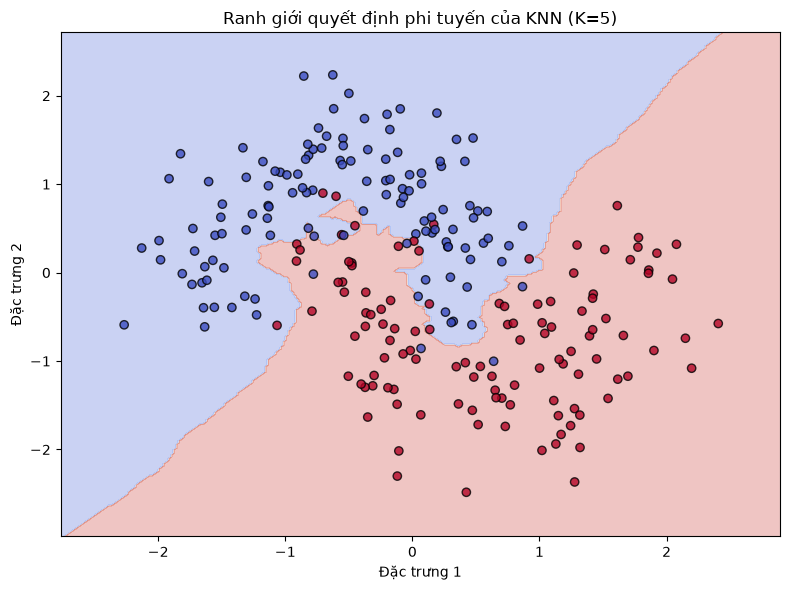

In [3]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.datasets import make_moons
from utils.metrics import accuracy_score
from utils.preprocessing import StandardScaler, train_test_split

# 1. Sinh dữ liệu phi tuyến (Hai mặt trăng lồng vào nhau)
X, y = make_moons(n_samples=300, noise=0.25, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Chuẩn hóa dữ liệu (Đặc biệt quan trọng với KNN vì dựa trên khoảng cách)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Huấn luyện model Scratch
t0 = time.time()
model_scratch = KNNClassifier(k=5).fit(X_train_scaled, y_train)
t_scratch = (time.time() - t0) * 1000

# 4. Huấn luyện model Sklearn (algorithm='brute' để so sánh công bằng với cách code ma trận)
t0 = time.time()
model_sklearn = KNeighborsClassifier(n_neighbors=5, algorithm='brute').fit(X_train_scaled, y_train)
t_sklearn = (time.time() - t0) * 1000

# 5. Đánh giá
y_pred_scratch = model_scratch.predict(X_test_scaled)
y_pred_sklearn = model_sklearn.predict(X_test_scaled)

print(f"{'Metric':<20} | {'Scratch':<15} | {'Sklearn':<15}")
print("-" * 55)
print(f"{'Accuracy Score':<20} | {accuracy_score(y_test, y_pred_scratch):<15.4f} | {accuracy_score(y_test, y_pred_sklearn):<15.4f}")
print(f"{'Time (ms)':<20} | {t_scratch:<15.2f} | {t_sklearn:<15.2f}")

# 6. Trực quan hóa ranh giới phi tuyến
plt.figure(figsize=(8, 6))

x_min, x_max = X_train_scaled[:, 0].min() - 0.5, X_train_scaled[:, 0].max() + 0.5
y_min, y_max = X_train_scaled[:, 1].min() - 0.5, X_train_scaled[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))

Z = model_scratch.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
plt.scatter(X_train_scaled[:, 0], X_train_scaled[:, 1], c=y_train, cmap='coolwarm', edgecolors='k', alpha=0.8)
plt.title("Ranh giới quyết định phi tuyến của KNN (K=5)")
plt.xlabel("Đặc trưng 1")
plt.ylabel("Đặc trưng 2")

plt.tight_layout()
plt.show()